# Les jeunes sont-ils réellement plus inquiets du changement climatique, et est-ce que ça se traduit en comportements ?

**Données :** European Social Survey, vague 8 (2016), sous-ensemble fourni — 44 387 répondants, 23 pays.

**Article de référence :** Gregersen, T., Doran, R., Böhm, G., Tvinnereim, E. & Poortinga, W. (2020). *Political Orientation Moderates the Relationship Between Climate Change Beliefs and Worry About Climate Change.* Frontiers in Psychology, 11:1573. [doi:10.3389/fpsyg.2020.01573](https://doi.org/10.3389/fpsyg.2020.01573). Les auteurs utilisent exactement les mêmes données (ESS8, 23 pays) et montrent que l'inquiétude dépend surtout de deux **croyances** — l'origine humaine du changement climatique et la gravité de ses impacts — et que ce lien est **plus faible chez les personnes de droite**. Nous reprenons leurs variables (`ccgdbd`, `lrscale`, `eisced`) et leur modèle multiniveau, puis nous les appliquons à notre question sur les jeunes.

**Démarche :**
1. Préparation des données (recodages, groupes d'âge, pondération).
2. **Inquiétude** : les jeunes (15-29 ans) sont-ils plus inquiets que leurs aînés ? Et en matière de perception (cause humaine, impacts, responsabilité personnelle) ?
3. **Croyances et orientation politique** : réplication du modèle de Gregersen et al. (2020), puis décomposition de l'écart jeunes / aînés.
4. **Comportements** : économies d'énergie, achats, engagement politique (pétition, manifestation, boycott), soutien aux politiques climatiques.
5. **Lien inquiétude → comportement** : l'inquiétude se traduit-elle en actes, et ce lien est-il différent chez les jeunes ?

Les statistiques descriptives sont pondérées par `anweight` (= `pspwght` × `pweight`, la combinaison post-stratification × population utilisée aussi par Gregersen et al.). Les régressions ne sont pas pondérées (comme dans l'article) et incluent des effets fixes pays ; le modèle de la partie 3 est un modèle multiniveau (pays en effet aléatoire).

In [1]:
import numpy as np
import pandas as pd
import pyreadstat
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import warnings
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from pathlib import Path

pd.set_option('display.float_format', '{:.3f}'.format)
warnings.simplefilter('ignore', FutureWarning)
FIG = Path('figures'); FIG.mkdir(exist_ok=True)

# Palette (bleu = jeunes, gris = reste de la population)
BLUE, ORANGE, AQUA, PURPLE, GREY, TXT, TXT2 = '#257de0', '#f47230', '#00b894', '#8e5bd6', '#9a9a9a', '#191919', '#666666'
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.edgecolor': '#cccccc',
    'axes.labelcolor': TXT2, 'xtick.color': TXT2, 'ytick.color': TXT2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': '#eeeeee', 'grid.linewidth': 0.8,
    'axes.titleweight': 'bold', 'axes.titlesize': 11, 'axes.titlelocation': 'left',
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
})

## 1. Chargement et préparation des données

In [2]:
cols = ['cntry', 'anweight', 'agea', 'gndr', 'eduyrs', 'eisced', 'mnactic',
        'wrclmch', 'ccrdprs', 'ccnthum', 'ccgdbd',             # perception
        'lrscale',                                             # orientation politique
        'rdcenr', 'eneffap',                                   # comportements énergie
        'sgnptit', 'pbldmn', 'bctprd',                         # engagement politique
        'inctxff', 'sbsrnen', 'banhhap']                       # soutien aux politiques
df, meta = pyreadstat.read_sav('data/ESS8e02_3-subset.sav', usecols=cols)
print(df.shape)
df.head()

(44387, 20)


,cntry,anweight,sgnptit,pbldmn,bctprd,lrscale,eneffap,rdcenr,ccnthum,ccrdprs,wrclmch,ccgdbd,inctxff,sbsrnen,banhhap,gndr,agea,eisced,eduyrs,mnactic
0,AT,0.437,1.000,2.000,1.000,0.000,8.000,4.000,4.000,8.000,4.000,10.000,1.000,1.000,2.000,2.000,34.000,7.000,21.000,2.000
1,AT,0.333,2.000,2.000,1.000,1.000,10.000,5.000,4.000,7.000,4.000,2.000,1.000,2.000,2.000,1.000,52.000,4.000,16.000,1.000
2,AT,0.117,2.000,2.000,1.000,5.000,9.000,4.000,4.000,8.000,4.000,2.000,4.000,2.000,2.000,2.000,68.000,3.000,13.000,6.000
3,AT,0.175,2.000,2.000,2.000,0.000,10.000,4.000,3.000,6.000,3.000,7.000,3.000,3.000,3.000,1.000,54.000,3.000,12.000,1.000
4,AT,0.832,2.000,2.000,2.000,5.000,10.000,6.000,4.000,6.000,4.000,5.000,3.000,1.000,4.000,2.000,20.000,3.000,13.000,3.000


Les non-réponses (refus, ne sait pas…) sont déjà converties en `NaN` à la lecture. Il reste trois codes « hors échelle » à neutraliser :
- `rdcenr = 55` : « ne peut pas réduire sa consommation » ;
- `ccnthum = 55` : « je ne pense pas que le climat change » (traité comme manquant, comme dans Gregersen et al.) ;
- `eisced = 55` (« autre ») et `0` (non harmonisable).

**Variables ajoutées d'après Gregersen et al. (2020) :**
- `ccgdbd` — impact du changement climatique sur les populations du monde, de 0 (extrêmement mauvais) à 10 (extrêmement bon). On l'inverse en `impact` (10 = extrêmement mauvais) et, comme l'article, on le dichotomise : `impact_neg = 1` si l'impact est jugé plutôt mauvais (6-10 sur l'échelle inversée), 0 s'il est jugé neutre ou bon.
- `lrscale` — auto-positionnement gauche-droite de 0 (gauche) à 10 (droite). On crée aussi `gauche` (0-3), `droite` (7-10) et `lr_nr` (ne se positionne pas : ≈ 13 % de non-réponse, davantage en Europe centrale et orientale).
- `eisced` — niveau d'éducation harmonisé ES-ISCED (1 = inférieur au secondaire … 7 = master ou plus). **Il remplace `eduyrs` comme contrôle d'éducation** : c'est la mesure recommandée par l'ESS pour comparer les pays, et `eduyrs` contient des valeurs aberrantes (jusqu'à 54 ans d'études).

On construit ensuite des indicateurs binaires faciles à lire (en %).

In [3]:
df.loc[df.rdcenr == 55, 'rdcenr'] = np.nan
df.loc[df.ccnthum == 55, 'ccnthum'] = np.nan
df.loc[df.eisced.isin([0, 55]), 'eisced'] = np.nan
df = df[df.agea.notna()].copy()

df['age_grp'] = pd.cut(df.agea, [14, 29, 44, 59, 74, 120],
                       labels=['15-29', '30-44', '45-59', '60-74', '75+'])
df['jeune'] = (df.agea < 30).astype(int)
df['femme'] = (df.gndr == 2).astype(int)
df['etudiant'] = (df.mnactic == 2).astype(int)

def binaire(cond, src):
    return cond.astype(float).where(df[src].notna())

# Perception
df['inquiet']      = binaire(df.wrclmch >= 4, 'wrclmch')   # très / extrêmement inquiet
df['cause_humaine']= binaire(df.ccnthum >= 4, 'ccnthum')   # principalement / entièrement humaine
df['responsable']  = binaire(df.ccrdprs >= 7, 'ccrdprs')   # responsabilité perso >= 7/10
df['impact']       = 10 - df.ccgdbd                          # 0 = très bon … 10 = très mauvais
df['impact_neg']   = binaire(df.impact >= 6, 'ccgdbd')       # impact plutôt mauvais (Gregersen et al.)
# Orientation politique
df['gauche']       = binaire(df.lrscale <= 3, 'lrscale')
df['droite']       = binaire(df.lrscale >= 7, 'lrscale')
df['lr_nr']        = df.lrscale.isna().astype(float)         # ne se positionne pas
# Comportements
df['eco_energie']  = binaire(df.rdcenr >= 4, 'rdcenr')     # souvent / très souvent / toujours
df['achat_eff']    = binaire(df.eneffap >= 8, 'eneffap')   # achat appareil efficace probable (>= 8/10)
df['petition']     = binaire(df.sgnptit == 1, 'sgnptit')
df['manif']        = binaire(df.pbldmn == 1, 'pbldmn')
df['boycott']      = binaire(df.bctprd == 1, 'bctprd')
# Soutien aux politiques (1-2 = plutôt / très favorable)
df['pour_taxe']    = binaire(df.inctxff <= 2, 'inctxff')
df['pour_subv']    = binaire(df.sbsrnen <= 2, 'sbsrnen')
df['pour_interd']  = binaire(df.banhhap <= 2, 'banhhap')

# Variables centrées sur la moyenne générale (comme dans l'article)
for v in ['ccnthum', 'lrscale', 'agea', 'eisced']:
    df[v + '_c'] = df[v] - df[v].mean()
# Régions : pays post-communistes vs reste de l'échantillon (Europe de l'Ouest et Israël)
EST = ['CZ', 'EE', 'HU', 'LT', 'PL', 'RU', 'SI']
df['region'] = np.where(df.cntry.isin(EST), 'Ex-bloc communiste', 'Ouest et Israël')

print(df.age_grp.value_counts().sort_index())
print(df[['ccnthum', 'lrscale', 'agea', 'eisced']].mean().round(2))

age_grp
15-29     8095
30-44    10477
45-59    11281
60-74    10170
75+       4209
Name: count, dtype: int64
ccnthum    3.420
lrscale    5.160
agea      49.140
eisced     4.010
dtype: float64


In [4]:
def wmean(g, v):
    m = g[v].notna()
    return np.average(g.loc[m, v], weights=g.loc[m, 'anweight'])

def tableau(vars_, by='age_grp'):
    return pd.DataFrame({v: df.groupby(by, observed=True).apply(lambda g: wmean(g, v)) for v in vars_}).T

## 2. Les jeunes sont-ils plus inquiets ?

### 2.1 Comparaison par groupe d'âge (moyennes pondérées)
`wrclmch` : inquiétude de 1 (pas du tout) à 5 (extrêmement) ; `ccrdprs` : responsabilité personnelle de 0 à 10 ; `impact` : gravité perçue des impacts de 0 (très bons) à 10 (très mauvais).

In [5]:
perc = tableau(['wrclmch', 'inquiet', 'ccrdprs', 'responsable', 'cause_humaine', 'impact', 'impact_neg'])
perc

age_grp,15-29,30-44,45-59,60-74,75+
wrclmch,3.044,3.056,3.124,3.069,2.930
inquiet,0.294,0.294,0.313,0.299,0.268
ccrdprs,5.494,5.656,5.802,5.543,4.814
responsable,0.380,0.432,0.455,0.424,0.329
cause_humaine,0.522,0.486,0.459,0.404,0.379
impact,6.813,6.952,6.856,6.672,6.475
impact_neg,0.721,0.736,0.715,0.686,0.633


In [6]:
# Distribution complète de l'inquiétude : jeunes vs 30 ans et plus
labels = ['Pas du tout', 'Pas très', 'Assez', 'Très', 'Extrêmement']
dist = (df.dropna(subset=['wrclmch'])
          .groupby(['jeune', 'wrclmch'])['anweight'].sum()
          .groupby(level=0).transform(lambda s: s / s.sum()).unstack())
dist.index = ['30 ans et +', '15-29 ans']; dist.columns = labels
(dist * 100).round(1)

,Pas du tout,Pas très,Assez,Très,Extrêmement
30 ans et +,5.500,18.000,46.600,23.900,6.000
15-29 ans,6.000,19.200,45.500,23.200,6.200


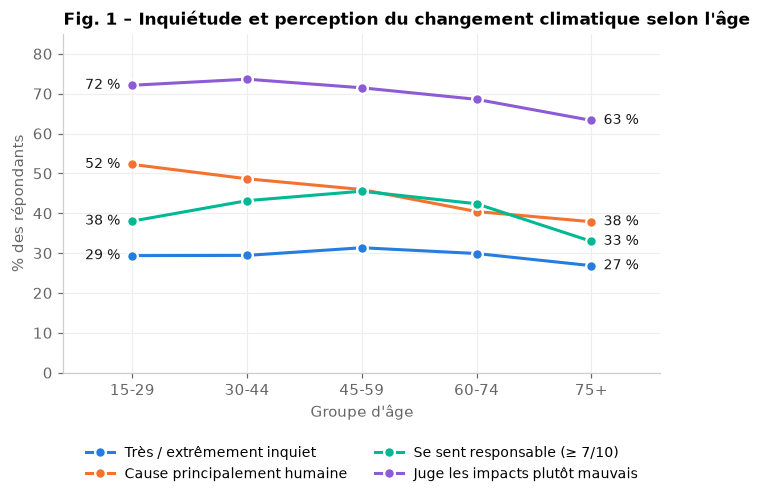

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(5)
series = [('inquiet', 'Très / extrêmement inquiet', BLUE),
          ('cause_humaine', 'Cause principalement humaine', ORANGE),
          ('responsable', 'Se sent responsable (≥ 7/10)', AQUA),
          ('impact_neg', 'Juge les impacts plutôt mauvais', PURPLE)]
for v, lab, col in series:
    y = perc.loc[v].values * 100
    ax.plot(x, y, color=col, lw=2, marker='o', ms=7, mec='white', mew=1.5, label=lab)
    ax.annotate(f'{y[0]:.0f} %', (x[0], y[0]), xytext=(-8, 0), textcoords='offset points',
                ha='right', va='center', color=TXT, fontsize=9)
    ax.annotate(f'{y[-1]:.0f} %', (x[-1], y[-1]), xytext=(8, 0), textcoords='offset points',
                ha='left', va='center', color=TXT, fontsize=9)
ax.set_xticks(x, perc.columns); ax.set_xlim(-0.6, 4.6); ax.set_ylim(0, 85)
ax.set_xlabel("Groupe d'âge"); ax.set_ylabel('% des répondants')
ax.set_title("Fig. 1 – Inquiétude et perception du changement climatique selon l'âge")
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=9)
fig.savefig(FIG / 'fig1_perception_age.png'); plt.show()

**Lecture :** l'inquiétude est remarquablement **stable avec l'âge** : environ 30 % des 15-29 ans se disent très ou extrêmement inquiets, soit autant que les 30-74 ans. Seuls les 75 ans et plus sont un peu moins inquiets. La responsabilité personnelle suit un profil en cloche (maximum vers 45-59 ans).

Les deux **croyances** étudiées par Gregersen et al. (2020) évoluent différemment : la **conviction que le changement climatique est d'origine humaine** décroît nettement avec l'âge (52 % chez les 15-29 ans, 38 % chez les 75 ans et plus) ; la perception d'**impacts plutôt mauvais** est majoritaire à tous les âges (72-74 % avant 60 ans) et ne recule qu'ensuite (63 % chez les 75 ans et plus).

### 2.2 Test : l'écart jeunes / aînés est-il significatif ?
Régression linéaire (MCO) avec contrôles (sexe, niveau d'éducation ES-ISCED) et effets fixes pays, erreurs-types robustes. Le coefficient `jeune` mesure l'écart moyen entre les 15-29 ans et les 30 ans et plus, à pays, sexe et éducation comparables.

In [8]:
CTRL = 'femme + eisced + C(cntry)'

def effet_jeune(y, extra='', data=None):
    data = df if data is None else data
    r = smf.ols(f'{y} ~ jeune + {CTRL}{extra}', data=data).fit(cov_type='HC1')
    lo, hi = r.conf_int().loc['jeune']
    return pd.Series({'coef_jeune': r.params['jeune'], 'IC95_bas': lo, 'IC95_haut': hi,
                      'p_value': r.pvalues['jeune'], 'n': int(r.nobs)})

res_perc = pd.DataFrame({y: effet_jeune(y) for y in
                         ['wrclmch', 'inquiet', 'ccrdprs', 'cause_humaine', 'impact_neg', 'lrscale']}).T
res_perc

,coef_jeune,IC95_bas,IC95_haut,p_value,n
wrclmch,0.045,0.022,0.067,0.000,42344.000
inquiet,0.022,0.011,0.033,0.000,42344.000
ccrdprs,0.061,0.001,0.122,0.048,41630.000
cause_humaine,0.106,0.093,0.118,0.000,41591.000
impact_neg,0.042,0.031,0.053,0.000,40948.000
lrscale,-0.106,-0.162,-0.051,0.000,38317.000


In [9]:
# Robustesse : même modèle avec l'ancien contrôle d'éducation (années d'études)
pd.DataFrame({'contrôle eisced': res_perc.coef_jeune,
              'contrôle eduyrs': [smf.ols(f'{y} ~ jeune + femme + eduyrs + C(cntry)', df).fit().params['jeune']
                                  for y in res_perc.index]})

,contrôle eisced,contrôle eduyrs
wrclmch,0.045,0.023
inquiet,0.022,0.014
ccrdprs,0.061,-0.021
cause_humaine,0.106,0.097
impact_neg,0.042,0.031
lrscale,-0.106,-0.092


L'écart d'inquiétude (`wrclmch`) est **minuscule** : +0,045 point sur une échelle de 1 à 5 (≈ 5 % d'écart-type), soit +2,2 points de % de « très / extrêmement inquiets ». Il est statistiquement significatif grâce à la taille de l'échantillon, mais sans portée pratique. La responsabilité personnelle ne diffère quasiment pas (+0,06 sur 10, p = 0,05). En revanche, les jeunes ont **10,6 points de % de plus** de chances d'attribuer le changement climatique à l'activité humaine, 4,2 points de plus de juger ses impacts plutôt mauvais, et se placent un peu plus à gauche (−0,11 point sur l'échelle 0-10).

*Changement de variable :* le contrôle d'éducation est désormais `eisced` (niveau harmonisé, comme dans l'article) et non plus `eduyrs`. Les écarts d'inquiétude sont un peu plus grands avec `eisced` (les jeunes n'ont pas encore atteint leur niveau d'études final, et `eisced` le capte mieux), mais restent négligeables avec les deux mesures ; les conclusions sont inchangées.

### 2.3 Cela dépend-il du pays ?

In [10]:
gap = df.groupby(['cntry', 'jeune']).apply(lambda g: wmean(g, 'wrclmch')).unstack()
gap.columns = ['30_et_plus', '15_29']
gap['ecart'] = gap['15_29'] - gap['30_et_plus']
PAYS = {'AT':'Autriche','BE':'Belgique','CH':'Suisse','CZ':'Tchéquie','DE':'Allemagne','EE':'Estonie','ES':'Espagne',
        'FI':'Finlande','FR':'France','GB':'Royaume-Uni','HU':'Hongrie','IE':'Irlande','IL':'Israël','IS':'Islande',
        'IT':'Italie','LT':'Lituanie','NL':'Pays-Bas','NO':'Norvège','PL':'Pologne','PT':'Portugal','RU':'Russie',
        'SE':'Suède','SI':'Slovénie'}
gap.index = gap.index.map(PAYS)
gap = gap.sort_values('ecart')
gap.T

cntry,Lituanie,Hongrie,Espagne,Tchéquie,Israël,Russie,Allemagne,Italie,Suisse,Slovénie,...,France,Belgique,Finlande,Portugal,Royaume-Uni,Irlande,Estonie,Norvège,Suède,Islande
30_et_plus,2.860,3.073,3.431,2.781,2.658,2.757,3.369,3.215,3.129,3.165,...,3.199,3.153,3.035,3.461,2.929,2.796,2.607,2.944,2.805,3.026
15_29,2.670,2.933,3.367,2.725,2.615,2.717,3.332,3.187,3.106,3.170,...,3.258,3.212,3.120,3.573,3.089,2.974,2.815,3.171,3.036,3.447
ecart,-0.191,-0.140,-0.064,-0.056,-0.043,-0.040,-0.038,-0.029,-0.023,0.005,...,0.059,0.059,0.085,0.112,0.160,0.178,0.208,0.227,0.231,0.421


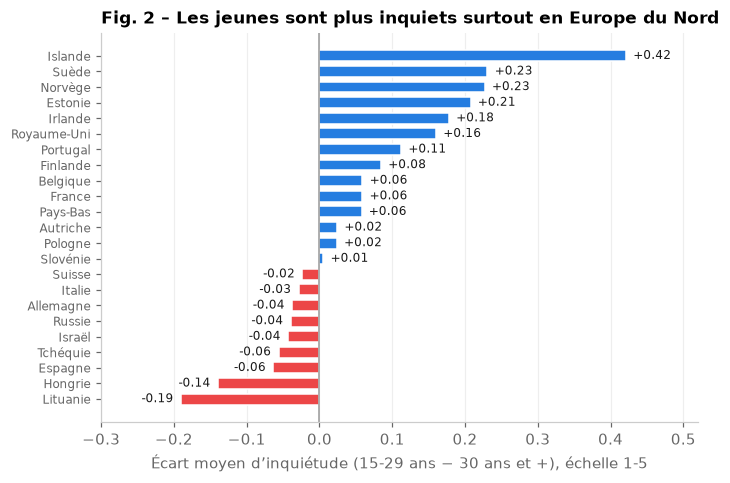

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.6))
cols_ = [BLUE if e > 0 else '#ec4647' for e in gap.ecart]
ax.barh(gap.index, gap.ecart, color=cols_, height=0.7, edgecolor='white', linewidth=1)
ax.axvline(0, color='#999999', lw=1)
for i, e in enumerate(gap.ecart):
    ax.text(e + (0.01 if e > 0 else -0.01), i, f'{e:+.2f}', va='center',
            ha='left' if e > 0 else 'right', fontsize=8, color=TXT)
ax.set_xlim(-0.3, 0.52); ax.grid(axis='y', visible=False)
ax.set_xlabel('Écart moyen d’inquiétude (15-29 ans − 30 ans et +), échelle 1-5')
ax.set_title('Fig. 2 – Les jeunes sont plus inquiets surtout en Europe du Nord')
ax.tick_params(axis='y', labelsize=8)
fig.savefig(FIG / 'fig2_ecart_pays.png'); plt.show()

**Lecture :** la moyenne européenne cache des situations opposées. Dans les pays nordiques et anglo-saxons (Islande, Suède, Norvège, Irlande, Royaume-Uni) et en Estonie, les jeunes sont nettement plus inquiets. En Europe centrale et orientale (Lituanie, Hongrie, Tchéquie, Russie) et en Espagne, c'est l'inverse. La France est proche de zéro (+0,06). La partie 3 montre que cet écart régional s'explique par les croyances.

## 3. Croyances, orientation politique et inquiétude : les apports de Gregersen et al. (2020)

Gregersen et al. (2020) expliquent l'inquiétude (`wrclmch`) par :
- l'**attribution** du changement climatique à l'activité humaine (`ccnthum`, 1-5, centrée) ;
- la perception d'**impacts plutôt mauvais** (`impact_neg`, 0/1) ;
- l'**orientation politique** (`lrscale`, 0-10, centrée), ainsi que ses interactions avec les deux croyances ;
- des contrôles : âge, sexe, éducation (`eisced`, centrée).

Le modèle est multiniveau (individus dans 23 pays, constante aléatoire par pays ; modèle 3 : pente aléatoire de l'orientation politique), estimé par maximum de vraisemblance, non pondéré.

### 3.1 Les jeunes se situent-ils plus à gauche ?

In [12]:
pol = tableau(['lrscale', 'gauche', 'droite', 'lr_nr'])
pol

age_grp,15-29,30-44,45-59,60-74,75+
lrscale,4.905,4.944,5.000,4.963,5.376
gauche,0.225,0.225,0.220,0.235,0.194
droite,0.188,0.208,0.222,0.232,0.311
lr_nr,0.196,0.184,0.162,0.160,0.209


**Lecture :** les jeunes ne sont que **légèrement plus à gauche** (moyenne 4,9 contre 5,0 chez les 30-74 ans et 5,4 chez les 75 ans et plus). La différence tient surtout à ce qu'ils sont **moins souvent à droite** (19 % se placent entre 7 et 10, contre 31 % des 75 ans et plus) ; la part de personnes à gauche est la même à tous les âges (≈ 22 %). Les jeunes refusent aussi plus souvent de se positionner (20 % contre 16 % des 45-74 ans). Ces non-réponses sont exclues des modèles qui utilisent `lrscale`.

### 3.2 Réplication du modèle multiniveau

In [13]:
VARS_R = ['wrclmch', 'ccnthum', 'impact_neg', 'lrscale', 'agea', 'femme', 'eisced']
dm = df.dropna(subset=VARS_R).copy()
print(f'N = {len(dm):,} individus, {dm.cntry.nunique()} pays (article : N = 35 690)')

BASE = 'wrclmch ~ ccnthum_c + impact_neg + lrscale_c + agea_c + femme + eisced_c'
INTER = ' + ccnthum_c:lrscale_c + impact_neg:lrscale_c'
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    m0 = smf.mixedlm('wrclmch ~ 1', dm, groups='cntry').fit(reml=False)
    m1 = smf.mixedlm(BASE, dm, groups='cntry').fit(reml=False)
    m2 = smf.mixedlm(BASE + INTER, dm, groups='cntry').fit(reml=False)
    m3 = smf.mixedlm(BASE + INTER, dm, groups='cntry', re_formula='~lrscale_c').fit(reml=False)

# Coefficients publiés (Tableau 3 de l'article)
ARTICLE = {'M1': {'ccnthum_c': .29, 'impact_neg': .31, 'lrscale_c': -.03, 'agea_c': .00, 'femme': .12, 'eisced_c': .02},
           'M2': {'ccnthum_c': .29, 'impact_neg': .32, 'lrscale_c': -.01, 'agea_c': .00, 'femme': .12, 'eisced_c': .02,
                  'ccnthum_c:lrscale_c': -.01, 'impact_neg:lrscale_c': -.03}}
NOMS_R = {'ccnthum_c': 'Attribution humaine (1-5)', 'impact_neg': 'Impacts plutôt mauvais (0/1)',
          'lrscale_c': 'Orientation politique (0 = gauche, 10 = droite)', 'agea_c': 'Âge (années)',
          'femme': 'Femme', 'eisced_c': 'Éducation (ES-ISCED 1-7)',
          'ccnthum_c:lrscale_c': 'Attribution × orientation', 'impact_neg:lrscale_c': 'Impacts × orientation'}
rep = pd.DataFrame({'M1 (nous)': m1.fe_params, 'M1 (article)': pd.Series(ARTICLE['M1']),
                    'M2 (nous)': m2.fe_params, 'p (M2)': m2.pvalues[m2.fe_params.index],
                    'M2 (article)': pd.Series(ARTICLE['M2'])}).loc[list(NOMS_R)]
rep.index = rep.index.map(NOMS_R)
rep

N = 35,694 individus, 23 pays (article : N = 35 690)


,M1 (nous),M1 (article),M2 (nous),p (M2),M2 (article)
Attribution humaine (1-5),0.286,0.290,0.286,0.000,0.290
Impacts plutôt mauvais (0/1),0.312,0.310,0.318,0.000,0.320
"Orientation politique (0 = gauche, 10 = droite)",-0.027,-0.030,-0.006,0.139,-0.010
Âge (années),-0.000,0.000,-0.000,0.945,0.000
Femme,0.117,0.120,0.117,0.000,0.120
Éducation (ES-ISCED 1-7),0.024,0.020,0.024,0.000,0.020
Attribution × orientation,NaN,NaN,-0.008,0.001,-0.010
Impacts × orientation,NaN,NaN,-0.029,0.000,-0.030


In [14]:
from scipy import stats

icc = lambda m: m.cov_re.iloc[0, 0] / (m.cov_re.iloc[0, 0] + m.scale)
def lr_test(a, b, ddl):
    chi2 = 2 * (b.llf - a.llf)
    p = stats.chi2.sf(chi2, ddl)
    return f'χ²({ddl}) = {chi2:.1f}, ' + ('p < 0,001' if p < 0.001 else f'p = {p:.3f}')

print(f'ICC modèle nul : {icc(m0):.3f} (article : 0,06)  |  ICC modèle 1 : {icc(m1):.3f}')
print(f'Variance pays : {m0.cov_re.iloc[0, 0]:.3f} → {m1.cov_re.iloc[0, 0]:.3f} ;'
      f' variance individuelle : {m0.scale:.3f} → {m1.scale:.3f}')
print(f'Pseudo-R² (réduction de la variance totale, M1) : '
      f'{1 - (m1.cov_re.iloc[0, 0] + m1.scale) / (m0.cov_re.iloc[0, 0] + m0.scale):.3f} (article : 0,138)')
print('M0 → M1 :', lr_test(m0, m1, 6), '| M1 → M2 :', lr_test(m1, m2, 2), '| M2 → M3 :', lr_test(m2, m3, 2))
print(f'M3 : variance de la pente « orientation » entre pays = {m3.cov_re.iloc[1, 1]:.5f}')

# Pentes simples : effet des croyances à gauche (0), au centre (5) et à droite (10)
pentes = pd.DataFrame({lr: {'Attribution humaine': m2.fe_params['ccnthum_c'] + (lr - df.lrscale.mean()) * m2.fe_params['ccnthum_c:lrscale_c'],
                            'Impacts plutôt mauvais': m2.fe_params['impact_neg'] + (lr - df.lrscale.mean()) * m2.fe_params['impact_neg:lrscale_c']}
                       for lr in [0, 5, 10]})
pentes.columns = ['Gauche (0)', 'Centre (5)', 'Droite (10)']
pentes

ICC modèle nul : 0.059 (article : 0,06)  |  ICC modèle 1 : 0.046
Variance pays : 0.049 → 0.033 ; variance individuelle : 0.774 → 0.676
Pseudo-R² (réduction de la variance totale, M1) : 0.138 (article : 0,138)
M0 → M1 : χ²(6) = 4824.5, p < 0,001 | M1 → M2 : χ²(2) = 64.0, p < 0,001 | M2 → M3 : χ²(2) = 6.6, p = 0.038
M3 : variance de la pente « orientation » entre pays = 0.00009


,Gauche (0),Centre (5),Droite (10)
Attribution humaine,0.328,0.287,0.247
Impacts plutôt mauvais,0.466,0.322,0.178


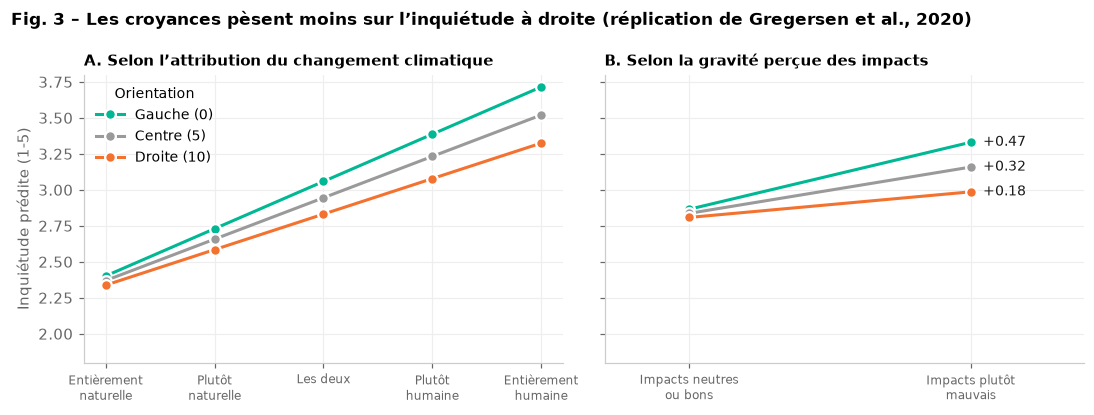

In [15]:
# Fig. 3 – Valeurs prédites par le modèle 2 (autres variables à leur moyenne)
def pred(**kw):
    new = pd.DataFrame({'ccnthum_c': 0.0, 'impact_neg': dm.impact_neg.mean(), 'lrscale_c': 0.0,
                        'agea_c': 0.0, 'femme': dm.femme.mean(), 'eisced_c': 0.0}, index=[0])
    for k, v in kw.items():
        new[k] = v
    return m2.predict(new).iloc[0]

LR_COLS = [(0, 'Gauche (0)', AQUA), (5, 'Centre (5)', GREY), (10, 'Droite (10)', ORANGE)]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
ax = axes[0]; att = np.arange(1, 6)
for lr, lab, col in LR_COLS:
    y = [pred(ccnthum_c=a - df.ccnthum.mean(), lrscale_c=lr - df.lrscale.mean()) for a in att]
    ax.plot(att, y, color=col, lw=2, marker='o', ms=7, mec='white', mew=1.5, label=lab)
ax.set_xticks(att, ['Entièrement\nnaturelle', 'Plutôt\nnaturelle', 'Les deux', 'Plutôt\nhumaine', 'Entièrement\nhumaine'], fontsize=8)
ax.set_title('A. Selon l’attribution du changement climatique', fontsize=10)
ax.set_ylabel('Inquiétude prédite (1-5)'); ax.legend(frameon=False, fontsize=9, title='Orientation', title_fontsize=9)
ax = axes[1]; x = np.arange(2)
for lr, lab, col in LR_COLS:
    y = [pred(impact_neg=i, lrscale_c=lr - df.lrscale.mean()) for i in [0, 1]]
    ax.plot(x, y, color=col, lw=2, marker='o', ms=7, mec='white', mew=1.5, label=lab)
    ax.annotate(f'+{y[1] - y[0]:.2f}', (1, y[1]), xytext=(8, 0), textcoords='offset points',
                va='center', fontsize=9, color=TXT)
ax.set_xticks(x, ['Impacts neutres\nou bons', 'Impacts plutôt\nmauvais'], fontsize=8); ax.set_xlim(-0.3, 1.4)
ax.set_title('B. Selon la gravité perçue des impacts', fontsize=10)
axes[0].set_ylim(1.8, 3.8)
fig.suptitle('Fig. 3 – Les croyances pèsent moins sur l’inquiétude à droite (réplication de Gregersen et al., 2020)',
             x=0.01, ha='left', fontweight='bold', fontsize=11)
fig.tight_layout(); fig.savefig(FIG / 'fig3_croyances_politique.png'); plt.show()

**Lecture : la réplication est quasi parfaite.** Sur 35 694 répondants (35 690 dans l'article), on retrouve les coefficients publiés au centième près :
- l'**attribution humaine** est le premier facteur (+0,29 point d'inquiétude par point d'attribution) ;
- percevoir des **impacts plutôt mauvais** ajoute +0,31 point ;
- l'**orientation politique** a un léger effet direct (−0,03 par point vers la droite), qui disparaît une fois les interactions introduites (modèle 2) ;
- les **interactions** sont négatives et significatives : plus on est à droite, moins les croyances se traduisent en inquiétude. L'effet des impacts passe de +0,47 à l'extrême gauche à +0,18 à l'extrême droite ; celui de l'attribution de +0,33 à +0,25 (mêmes valeurs que l'article, fig. 3) ;
- **l'âge n'a aucun effet** (0,000) une fois les croyances prises en compte : c'est le point de départ de notre décomposition (§3.3).

Les statistiques d'ajustement sont aussi celles de l'article : ICC du modèle nul = 0,06 (6 % de la variance de l'inquiétude se situe entre pays), pseudo-R² = 0,138. Le modèle 3 (pente aléatoire de l'orientation politique) n'améliore que marginalement l'ajustement (χ²(2) = 6,6, p = 0,04 ; l'article trouve un gain plus net) et la variance de la pente est quasi nulle (l'article trouve aussi 0,00).

### 3.3 Pourquoi les jeunes, plus convaincus, ne sont-ils guère plus inquiets ?

Si l'attribution humaine est le premier moteur de l'inquiétude (article et §3.2) et que les jeunes y adhèrent nettement plus (§2.2), ils *devraient* être plus inquiets. On décompose donc l'écart jeunes / aînés : écart brut, puis à croyances égales (attribution, impacts), puis à orientation politique égale. Même échantillon pour les trois modèles (MCO, effets fixes pays, erreurs robustes), pour l'ensemble et par région, puisque l'article montre que la relation politique-inquiétude est plus faible dans les pays post-communistes.

In [16]:
SPECS = {'Écart brut': '',
         '+ croyances (attribution, impacts)': ' + ccnthum + impact_neg',
         '+ croyances + orientation politique': ' + ccnthum + impact_neg + lrscale'}
SAMPLES = {'Ensemble': dm, 'Ouest et Israël': dm[dm.region == 'Ouest et Israël'],
           'Ex-bloc communiste': dm[dm.region == 'Ex-bloc communiste']}
decomp = pd.concat({s: pd.DataFrame({k: effet_jeune('wrclmch', e, d) for k, e in SPECS.items()}).T
                    for s, d in SAMPLES.items()})
# Écart de croyances entre jeunes et aînés sur cet échantillon, et effet attendu sur l'inquiétude
ecart_croy = pd.Series({v: effet_jeune(v, data=dm)['coef_jeune'] for v in ['ccnthum', 'impact_neg']})
print('Écart jeunes - aînés : attribution', round(ecart_croy.ccnthum, 3), '| impacts', round(ecart_croy.impact_neg, 3))
print('Inquiétude « attendue » via les croyances (coef. M1) :',
      round(ecart_croy.ccnthum * m1.fe_params['ccnthum_c'] + ecart_croy.impact_neg * m1.fe_params['impact_neg'], 3))
decomp

Écart jeunes - aînés : attribution 0.141 | impacts 0.049
Inquiétude « attendue » via les croyances (coef. M1) : 0.055


coef_jeune  IC95_bas  \
Ensemble           Écart brut                                0.050     0.025   
                   + croyances (attribution, impacts)       -0.007    -0.030   
                   + croyances + orientation politique      -0.009    -0.032   
Ouest et Israël    Écart brut                                0.065     0.037   
                   + croyances (attribution, impacts)       -0.010    -0.036   
                   + croyances + orientation politique      -0.015    -0.041   
Ex-bloc communiste Écart brut                                0.009    -0.040   
                   + croyances (attribution, impacts)       -0.005    -0.052   
                   + croyances + orientation politique      -0.003    -0.050   

                                                        IC95_haut  p_value  \
Ensemble           Écart brut                               0.074    0.000   
                   + croyances (attribution, impacts)       0.017    0.575   
                   + croyances + orientation politique      0.014    0.463   
Ouest et Israël    Écart brut                               0.093    0.000   
                   + croyances (attribution, impacts)       0.017    0.486   
                   + croyances + orientation politique      0.012    0.285   
Ex-bloc communiste Écart brut                               0.058    0.723   
                   + croyances (attribution, impacts)       0.041    0.825   
                   + croyances + orientation politique      0.043    0.891   

                                                               n  
Ensemble           Écart brut                          35694.000  
                   + croyances (attribution, impacts)  35694.000  
                   + croyances + orientation politique 35694.000  
Ouest et Israël    Écart brut                          26110.000  
                   + croyances (attribution, impacts)  26110.000  
                   + croyances + orientation politique 26110.000  
Ex-bloc communiste Écart brut                           9584.000  
                   + croyances (attribution, impacts)   9584.000  
                   + croyances + orientation politique  9584.000

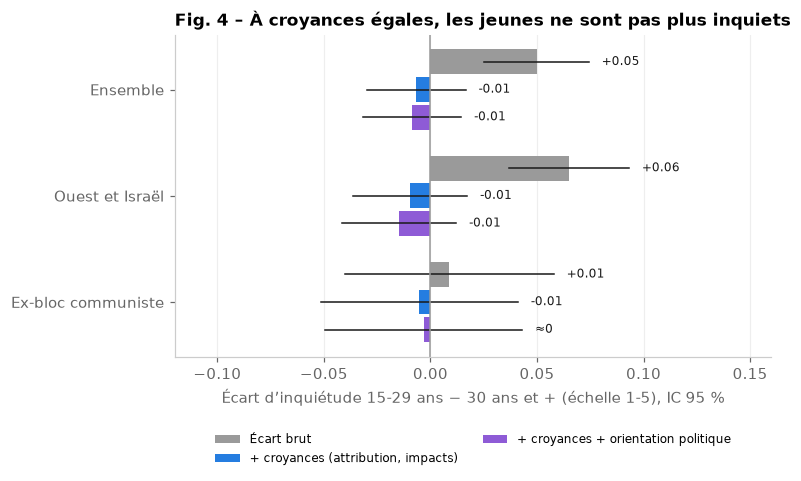

In [17]:
fig, ax = plt.subplots(figsize=(7, 3.8))
spec_cols = [GREY, BLUE, PURPLE]; h = 0.26
for i, s in enumerate(SAMPLES):
    for j, (k, col) in enumerate(zip(SPECS, spec_cols)):
        r = decomp.loc[(s, k)]; y = i + (j - 1) * h
        ax.barh(y, r.coef_jeune, h * 0.9, color=col, label=k if i == 0 else None)
        ax.plot([r.IC95_bas, r.IC95_haut], [y, y], color=TXT, lw=1)
        ax.text(max(r.IC95_haut, 0) + 0.006, y, f'{r.coef_jeune:+.2f}' if abs(r.coef_jeune) >= 0.005 else '≈0', va='center', fontsize=8, color=TXT)
ax.axvline(0, color='#999999', lw=1); ax.grid(axis='y', visible=False)
ax.set_yticks(range(len(SAMPLES)), list(SAMPLES)); ax.invert_yaxis(); ax.set_xlim(-0.12, 0.16)
ax.set_xlabel('Écart d’inquiétude 15-29 ans − 30 ans et + (échelle 1-5), IC 95 %')
ax.set_title('Fig. 4 – À croyances égales, les jeunes ne sont pas plus inquiets')
ax.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
fig.savefig(FIG / 'fig4_ecart_jeunes_croyances.png'); plt.show()

In [18]:
# Le rôle modérateur de l'orientation politique vaut-il aussi chez les jeunes ?
F_GRP = 'wrclmch ~ ccnthum_c * lrscale_c + impact_neg * lrscale_c + femme + eisced_c'
TERMES = ['ccnthum_c', 'impact_neg', 'lrscale_c', 'ccnthum_c:lrscale_c', 'impact_neg:lrscale_c']
grp = {}
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    for lab, j in [('15-29 ans', 1), ('30 ans et +', 0)]:
        m = smf.mixedlm(F_GRP, dm[dm.jeune == j], groups='cntry').fit(reml=False)
        grp[lab] = pd.concat([m.fe_params[TERMES], m.pvalues[TERMES].add_prefix('p ')])
grp = pd.DataFrame(grp)
grp

,15-29 ans,30 ans et +
ccnthum_c,0.275,0.288
impact_neg,0.355,0.310
lrscale_c,-0.015,-0.004
ccnthum_c:lrscale_c,-0.020,-0.006
impact_neg:lrscale_c,-0.027,-0.029
p ccnthum_c,0.000,0.000
p impact_neg,0.000,0.000
p lrscale_c,0.168,0.313
p ccnthum_c:lrscale_c,0.001,0.033
p impact_neg:lrscale_c,0.031,0.000


In [19]:
# Pente de l'orientation politique pays par pays (à âge, sexe et éducation égaux)
pente_pays = pd.Series({c: smf.ols('wrclmch ~ lrscale + agea + femme + eisced', g).fit().params['lrscale']
                        for c, g in dm.groupby('cntry')}).sort_values()
print(pente_pays.groupby(pente_pays.index.isin(EST)).mean().rename({False: 'Ouest et Israël', True: 'Ex-bloc communiste'}))
pente_pays.rename(PAYS).round(3).to_frame('pente gauche-droite').T

Ouest et Israël      -0.050
Ex-bloc communiste   -0.014
dtype: float64


,Royaume-Uni,Norvège,Islande,Suisse,Pays-Bas,Espagne,Allemagne,Suède,Israël,Finlande,...,France,Pologne,Estonie,Portugal,Tchéquie,Hongrie,Lituanie,Italie,Russie,Slovénie
pente gauche-droite,-0.088,-0.080,-0.072,-0.068,-0.065,-0.062,-0.056,-0.047,-0.046,-0.044,...,-0.034,-0.034,-0.029,-0.025,-0.019,-0.017,-0.008,-0.002,0.002,0.008


**Lecture : le léger surcroît d'inquiétude des jeunes s'explique entièrement par leurs croyances.**
- Sur l'ensemble des pays, l'écart brut est de +0,05 point ; **à attribution et perception des impacts égales, il tombe à −0,01 (non significatif)**. Le calcul est cohérent : les jeunes ont +0,14 point d'attribution humaine (× 0,29) et +4,9 points de % d'impacts négatifs (× 0,31), ce qui « prédit » +0,055 point d'inquiétude, soit exactement l'écart observé.
- En **Europe de l'Ouest** (et Israël), l'écart brut est plus marqué (+0,065) et disparaît aussi à croyances égales. Dans les pays **post-communistes**, il n'y a pas d'écart du tout.
- Contrôler en plus l'orientation politique ne change rien : être un peu plus à gauche n'explique pas l'inquiétude des jeunes.

Autrement dit, **il n'y a pas d'« anxiété climatique » propre à la jeunesse en 2016** : les jeunes s'inquiètent un peu plus *parce qu'ils sont plus convaincus* de l'origine humaine du phénomène. À conviction égale, un jeune est aussi inquiet qu'un aîné. Cela explique aussi le paradoxe de la partie 2 : un écart de 10 points sur l'attribution ne se traduit que par 0,05 point d'inquiétude, car il ne concerne qu'une partie des jeunes et que chaque point d'attribution « vaut » 0,29 point d'inquiétude.

**La modération politique vaut aussi chez les jeunes**, et même plus nettement pour l'attribution (interaction −0,020 contre −0,006 chez les 30 ans et plus, p = 0,001). Un jeune de droite convaincu de l'origine humaine du changement climatique s'en inquiète nettement moins qu'un jeune de gauche aussi convaincu.

Enfin, comme dans l'article, la pente gauche-droite est **plus forte à l'Ouest** (−0,050 en moyenne ; jusqu'à −0,09 au Royaume-Uni et en Norvège) que dans les pays **post-communistes** (−0,014 ; quasi nulle en Russie, Slovénie, Lituanie et Italie). Le clivage gauche-droite sur le climat est une spécificité des démocraties occidentales.

## 4. Les jeunes agissent-ils davantage ?

In [20]:
comp_vars = ['eco_energie', 'achat_eff', 'petition', 'manif', 'boycott', 'pour_taxe', 'pour_subv', 'pour_interd']
comp = tableau(comp_vars)
comp_j = tableau(comp_vars, by='jeune'); comp_j.columns = ['30 ans et +', '15-29 ans']
comp_j['écart (pts)'] = (comp_j['15-29 ans'] - comp_j['30 ans et +']) * 100
display(comp * 100)
comp_j

age_grp,15-29,30-44,45-59,60-74,75+
eco_energie,54.295,66.695,72.992,75.795,74.638
achat_eff,45.698,61.210,65.966,68.534,61.135
petition,23.877,26.265,25.102,22.093,13.241
manif,11.465,8.684,9.230,6.765,2.879
boycott,12.968,17.267,19.212,17.740,11.601
pour_taxe,34.527,30.529,28.811,26.457,24.503
pour_subv,76.066,74.065,74.772,70.453,70.638
pour_interd,49.511,57.332,63.190,61.572,59.306


,30 ans et +,15-29 ans,écart (pts)
eco_energie,0.719,0.543,-17.644
achat_eff,0.646,0.457,-18.939
petition,0.234,0.239,0.479
manif,0.077,0.115,3.727
boycott,0.174,0.130,-4.438
pour_taxe,0.283,0.345,6.220
pour_subv,0.730,0.761,3.038
pour_interd,0.606,0.495,-11.050


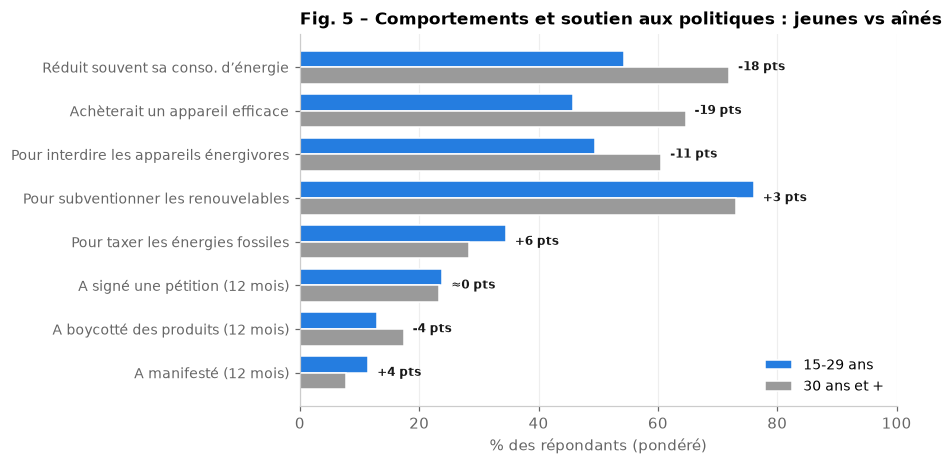

In [21]:
noms = {'eco_energie': 'Réduit souvent sa conso. d’énergie', 'achat_eff': 'Achèterait un appareil efficace',
        'pour_interd': 'Pour interdire les appareils énergivores', 'pour_subv': 'Pour subventionner les renouvelables',
        'pour_taxe': 'Pour taxer les énergies fossiles', 'petition': 'A signé une pétition (12 mois)',
        'boycott': 'A boycotté des produits (12 mois)', 'manif': 'A manifesté (12 mois)'}
ordre = ['eco_energie', 'achat_eff', 'pour_interd', 'pour_subv', 'pour_taxe', 'petition', 'boycott', 'manif'][::-1]
d = comp_j.loc[ordre]
fig, ax = plt.subplots(figsize=(7, 4.4))
y = np.arange(len(d)); h = 0.38
ax.barh(y + h/2, d['15-29 ans'] * 100, h, color=BLUE, label='15-29 ans', edgecolor='white', linewidth=1)
ax.barh(y - h/2, d['30 ans et +'] * 100, h, color=GREY, label='30 ans et +', edgecolor='white', linewidth=1)
for i, (a, b) in enumerate(zip(d['15-29 ans'], d['30 ans et +'])):
    ax.text(max(a, b) * 100 + 1.5, i, f'{(a - b) * 100:+.0f} pts'.replace('+0 ', '≈0 '), va='center', fontsize=8,
            color=TXT, fontweight='bold')
ax.set_yticks(y, [noms[v] for v in ordre], fontsize=9); ax.set_xlim(0, 100)
ax.grid(axis='y', visible=False); ax.set_xlabel('% des répondants (pondéré)')
ax.set_title('Fig. 5 – Comportements et soutien aux politiques : jeunes vs aînés')
ax.legend(frameon=False, loc='lower right', fontsize=9)
fig.savefig(FIG / 'fig5_comportements.png'); plt.show()

In [22]:
res_comp = pd.DataFrame({y: effet_jeune(y) for y in comp_vars}).T
res_comp

,coef_jeune,IC95_bas,IC95_haut,p_value,n
eco_energie,-0.136,-0.147,-0.124,0.000,43508.000
achat_eff,-0.162,-0.174,-0.150,0.000,42961.000
petition,0.029,0.019,0.039,0.000,43860.000
manif,0.030,0.023,0.037,0.000,43910.000
boycott,-0.019,-0.027,-0.011,0.000,43831.000
pour_taxe,0.054,0.042,0.065,0.000,42095.000
pour_subv,0.024,0.014,0.034,0.000,42673.000
pour_interd,-0.062,-0.075,-0.050,0.000,42394.000


**Lecture :** le tableau est contrasté.
- **Gestes du quotidien : les jeunes font moins.** Ils sont nettement moins nombreux à réduire souvent leur consommation d'énergie (−13,6 pts après contrôles) et à se dire prêts à acheter un appareil économe (−16,2 pts). Ils sont aussi moins favorables à l'interdiction des appareils énergivores (−6,2 pts).
- **Engagement politique et taxe carbone : les jeunes font plus.** Ils manifestent davantage (+3,0 pts), signent un peu plus de pétitions (+2,9 pts) et soutiennent plus la taxation des énergies fossiles (+5,4 pts) ; ils boycottent un peu moins (−1,9 pt).

Une partie de l'écart sur les gestes quotidiens relève sans doute de la **situation de vie** plutôt que des convictions : beaucoup de jeunes vivent chez leurs parents ou en colocation, ne paient pas les factures et n'achètent pas d'électroménager. On vérifie en contrôlant le statut d'étudiant, puis l'orientation politique et les croyances (variables de la partie 3) :

In [23]:
rob = pd.DataFrame({'contrôles de base': res_comp.coef_jeune,
                    '+ étudiant': [effet_jeune(y, ' + etudiant')['coef_jeune'] for y in comp_vars],
                    '+ orientation politique': [effet_jeune(y, ' + lrscale')['coef_jeune'] for y in comp_vars],
                    '+ orientation + croyances': [effet_jeune(y, ' + lrscale + ccnthum + impact_neg')['coef_jeune']
                                                  for y in comp_vars]}) * 100
rob.round(1)

,contrôles de base,+ étudiant,+ orientation politique,+ orientation + croyances
eco_energie,-13.600,-13.400,-13.200,-13.300
achat_eff,-16.200,-14.600,-17.400,-18.700
petition,2.900,0.700,3.100,2.500
manif,3.000,1.500,3.300,3.000
boycott,-1.900,-3.300,-2.200,-3.000
pour_taxe,5.400,1.300,5.400,4.300
pour_subv,2.400,-0.100,2.300,0.800
pour_interd,-6.200,-7.100,-6.800,-8.700


**Lecture :**
- **Gestes du quotidien :** l'écart ne bouge presque pas, quel que soit le contrôle (−13,6 → −13,4 pts pour l'énergie, −16,2 → −14,6 pts pour les achats avec le statut d'étudiant). Ni le statut d'étudiant, ni l'orientation politique, ni les croyances ne l'expliquent. D'autres facteurs de « cycle de vie » non mesurés ici (vivre chez ses parents, ne pas payer les factures) peuvent jouer.
- **Engagement politique et taxe carbone :** le surcroît des jeunes est **porté par les étudiants**. À statut d'étudiant égal, l'écart sur les pétitions tombe de +2,9 à +0,7 pt, sur la taxe de +5,4 à +1,3 pt, et sur les manifestations de +3,0 à +1,5 pt.
- **Orientation politique :** la contrôler ne change rien. Le plus fort engagement des jeunes ne vient pas de ce qu'ils seraient plus à gauche.

## 5. L'inquiétude se traduit-elle en actes ?

On regarde la part de personnes qui adoptent chaque comportement selon leur niveau d'inquiétude, séparément pour les jeunes et les aînés.

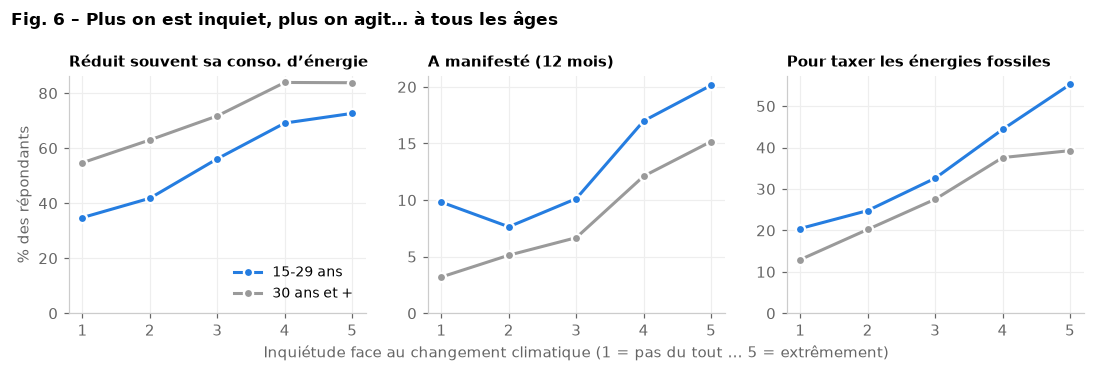

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), sharex=True)
for ax, (v, titre) in zip(axes, [('eco_energie', 'Réduit souvent sa conso. d’énergie'),
                                 ('manif', 'A manifesté (12 mois)'),
                                 ('pour_taxe', 'Pour taxer les énergies fossiles')]):
    t = df.dropna(subset=['wrclmch', v]).groupby(['jeune', 'wrclmch']).apply(lambda g: wmean(g, v)).unstack(0) * 100
    ax.plot(t.index, t[1], color=BLUE, lw=2, marker='o', ms=6, mec='white', mew=1.5, label='15-29 ans')
    ax.plot(t.index, t[0], color=GREY, lw=2, marker='o', ms=6, mec='white', mew=1.5, label='30 ans et +')
    ax.set_title(titre, fontsize=10); ax.set_xticks([1, 2, 3, 4, 5])
    ax.set_ylim(0, None)
axes[0].set_ylabel('% des répondants')
axes[1].set_xlabel('Inquiétude face au changement climatique (1 = pas du tout … 5 = extrêmement)')
axes[0].legend(frameon=False, fontsize=9, loc='lower right')
fig.suptitle('Fig. 6 – Plus on est inquiet, plus on agit… à tous les âges', x=0.01, ha='left',
             fontweight='bold', fontsize=11)
fig.tight_layout(); fig.savefig(FIG / 'fig6_inquietude_action.png'); plt.show()

### Régression avec interaction inquiétude × jeune
Modèle de probabilité linéaire : `comportement ~ inquiétude × jeune + sexe + éducation (ES-ISCED) + effets fixes pays`.
- `wrclmch` : effet d'un point d'inquiétude supplémentaire chez les 30 ans et + (en proportion) ;
- `wrclmch:jeune` : effet **supplémentaire** chez les jeunes (positif = le lien inquiétude → action est plus fort chez les jeunes).

In [25]:
rows = {}
for y in comp_vars:
    r = smf.ols(f'{y} ~ wrclmch * jeune + femme + eisced + C(cntry)', data=df).fit(cov_type='HC1')
    rows[y] = {'effet inquiétude (30+)': r.params['wrclmch'],
               'effet inquiétude (15-29)': r.params['wrclmch'] + r.params['wrclmch:jeune'],
               'différence': r.params['wrclmch:jeune'], 'p diff.': r.pvalues['wrclmch:jeune'],
               'R²': r.rsquared}
res_inter = pd.DataFrame(rows).T
res_inter

,effet inquiétude (30+),effet inquiétude (15-29),différence,p diff.,R²
eco_energie,0.073,0.094,0.021,0.001,0.068
achat_eff,0.067,0.064,-0.003,0.646,0.085
petition,0.048,0.059,0.011,0.043,0.138
manif,0.021,0.032,0.011,0.007,0.053
boycott,0.049,0.057,0.008,0.103,0.146
pour_taxe,0.075,0.098,0.023,0.000,0.094
pour_subv,0.057,0.068,0.011,0.050,0.065
pour_interd,0.089,0.087,-0.002,0.734,0.065


**Lecture :** pour **tous** les comportements, l'inquiétude est associée positivement à l'action, chez les jeunes comme chez les aînés : un point d'inquiétude en plus (sur 5) correspond à environ +7 points de % de chances de réduire souvent sa consommation d'énergie et +5 points pour signer une pétition. Le lien est **même un peu plus fort chez les jeunes** pour les économies d'énergie (+9,4 contre +7,3 pts), la manifestation et le soutien à la taxe sur les énergies fossiles (différences significatives à 1 %), ainsi que pour les pétitions (à 5 %). L'inquiétude n'est donc pas « déclarative » chez les jeunes : quand elle est présente, elle se traduit autant (voire plus) en actes. Les R² restent cependant faibles : l'inquiétude n'explique qu'une petite partie des comportements.

## 6. Conclusion

1. **En 2016, les jeunes Européens ne sont pas globalement plus inquiets** que leurs aînés (≈ 30 % très/extrêmement inquiets à tous les âges avant 75 ans). L'écart existe dans certains pays (Nord de l'Europe) et s'inverse dans d'autres (Europe centrale et orientale).
2. Ils se distinguent par une **plus forte conviction que le changement climatique est d'origine humaine** et, dans une moindre mesure, que ses impacts seront mauvais.
3. **Ces croyances expliquent entièrement leur léger surcroît d'inquiétude** : à croyances égales, un jeune n'est pas plus inquiet qu'un aîné. Comme le montrent Gregersen et al. (2020), dont nous reproduisons les résultats, l'attribution humaine est le premier moteur de l'inquiétude, et son effet est plus faible chez les personnes de droite. Cette modération politique vaut aussi chez les jeunes, et elle est plus marquée en Europe de l'Ouest.
4. **Côté comportements**, ils font **moins de gestes individuels** (énergie, achats) mais sont **plus engagés politiquement** (manifestations, soutien à la taxe sur les énergies fossiles), un surcroît porté par les étudiants et non par une orientation plus à gauche.
5. **L'inquiétude se traduit bien en comportements, à tous les âges**, et un peu plus fortement chez les jeunes.

**Limites :** données de 2016, *avant* les grèves pour le climat de 2018-2019 ; données en coupe transversale, qui ne permettent pas de séparer effet d'âge (cycle de vie) et effet de génération, ni d'établir le sens de la causalité entre croyances et inquiétude ; mesures à un seul item (inquiétude, attribution, impacts), comme le soulignent aussi Gregersen et al. ; question sur les impacts « pour les populations du monde », psychologiquement lointaine ; 13 % de non-réponse sur l'échelle gauche-droite (20 % chez les jeunes), dont le sens varie d'un pays à l'autre ; comportements **déclarés** ; manifestation, pétition et boycott ne sont pas spécifiquement climatiques ; modèles linéaires simples.